# Data Augmentation: Does It Help Our 2-Hidden-Layer Networks?

**Data augmentation** enlarges the training set with *modified copies* of the training examples (shifted, rotated, noisy...), keeping the label. The idea: the network should give the same answer for a "7" and for the same "7" moved by one pixel, but a plain MLP has no built-in way of knowing that. Each pixel is its own input, so a shifted digit is, to the network, a completely different vector.

```
 original "7"          shifted right by 1 pixel        what the MLP sees (flattened 64-vector)
 . . # # # # . .         . . . # # # # .               [0 0 1 1 1 1 0 0 | ...]   vs   [0 0 0 1 1 1 1 0 | ...]
 . . . . . # . .         . . . . . . # .               different inputs, SAME label
 . . . . # . . .         . . . . . # . .
```

So the honest questions are: **does augmentation help the small networks we have been using (an MLP with 2 hidden layers), on which kinds of data, and what does it cost?** We will find that the answer is *yes, but with conditions*.

**What you will do**

1. Implement shift / rotation / noise augmentation as one fast batched function and verify it against a slow reference
2. Train the **same 2-hidden-layer MLP with and without augmentation** on handwritten digits and compare accuracy on clean test images and on *shifted* test images
3. Sweep how often images are augmented, and see that augmentation **needs a longer training budget**
4. Test **which augmentation teaches which invariance** (a train-by-test table)
5. See how the effect changes with the **size of the training set**
6. Check whether the same idea helps on **tabular data** (breast cancer, wine)

It takes about 6 minutes on CPU.

## 0. Setup

In [1]:
import math
import random
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits, load_breast_cancer, load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

SEED = 0


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed()
torch.set_num_threads(1)          # tiny networks run fastest single-threaded on CPU
print("torch", torch.__version__)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

# scikit-learn digits: 8x8 images, pixel values scaled to [0, 1]. Fixed validation (300) and test (500) sets; the rest is a pool
# from which we draw small training sets, as in the dropout notebook.
digits = load_digits()
Xd = (digits.data / 16.0).astype(np.float32)
yd = digits.target.astype(np.int64)
X_pool, X_rest, y_pool, y_rest = train_test_split(Xd, yd, test_size=800, stratify=yd, random_state=SEED)
X_va, X_te, y_va, y_te = train_test_split(X_rest, y_rest, train_size=300, stratify=y_rest, random_state=SEED)
Xpool_t, ypool_t = torch.tensor(X_pool), torch.tensor(y_pool)
Xva_t, yva_t, Xte_t, yte_t = map(torch.tensor, (X_va, y_va, X_te, y_te))
print(f"pool={len(X_pool)}  val={len(X_va)}  test={len(X_te)}")

torch 2.15.0+cu132
pool=997  val=300  test=500


## 1. Augmentations, implemented as one fast batched function

Three kinds of change, each applied to a random subset of every training batch (a fresh random draw at every step, so the network essentially never sees the exact same image twice):

- **shift**: move the image by up to `max_shift` pixels in each direction, filling the border with 0 (background)
- **rotation**: rotate by a random angle in `[-max_rot, max_rot]` degrees about the center (bilinear interpolation)
- **noise**: add Gaussian noise of standard deviation `noise` to the pixels (then clip to [0, 1])

The geometric changes use PyTorch's `affine_grid` / `grid_sample`, which transforms the whole batch at once, much faster than looping over images. Because a bug here would silently invalidate every later result, we first check the shift against a slow, obviously-correct reference.

In [2]:
def transform(x, dx, dy, ang_deg, mode):
    """Batched geometric transform of flattened 8x8 images x [B, 64].
    The image CONTENT moves by dx pixels to the right and dy pixels down; ang_deg rotates about the center. dx, dy, ang_deg: [B]."""
    B = x.shape[0]
    a = ang_deg * math.pi / 180.0
    cos, sin = torch.cos(a), torch.sin(a)
    # affine_grid maps OUTPUT coordinates to INPUT coordinates; one pixel is 2/8 = 0.25 in normalized units
    theta = torch.stack([torch.stack([cos, -sin, -dx * 0.25], 1), torch.stack([sin, cos, -dy * 0.25], 1)], 1)
    grid = F.affine_grid(theta, (B, 1, 8, 8), align_corners=False)
    return F.grid_sample(x.view(B, 1, 8, 8), grid, mode=mode, padding_mode="zeros", align_corners=False).view(B, 64)


def augment(x, p=1.0, max_shift=0, max_rot=0.0, noise=0.0):
    """Each image is augmented with probability p (independently); the random parameters are drawn per image."""
    B = x.shape[0]
    apply = (torch.rand(B) < p).float()
    out = x
    if max_shift > 0 or max_rot > 0:
        dx = torch.randint(-max_shift, max_shift + 1, (B,)).float() * apply
        dy = torch.randint(-max_shift, max_shift + 1, (B,)).float() * apply
        ang = (torch.rand(B) * 2 - 1) * max_rot * apply
        out = transform(x, dx, dy, ang, "bilinear" if max_rot > 0 else "nearest")
    if noise > 0:
        out = (out + noise * torch.randn_like(out) * apply[:, None]).clamp(0, 1)
    return out


def shift_reference(img, dx, dy):
    """Slow reference: out[i, j] = img[i - dy, j - dx] if that pixel exists, else 0."""
    out = torch.zeros_like(img)
    for i in range(8):
        for j in range(8):
            si, sj = i - dy, j - dx
            if 0 <= si < 8 and 0 <= sj < 8:
                out[i, j] = img[si, sj]
    return out


# verify on real digits, for every shift in {-1, 0, 1}^2 and for a 2-pixel shift as well
worst = 0.0
imgs = Xpool_t[:20]
for dx in (-2, -1, 0, 1, 2):
    for dy in (-2, -1, 0, 1, 2):
        fast = transform(imgs, torch.full((20,), float(dx)), torch.full((20,), float(dy)), torch.zeros(20), "nearest")
        ref = torch.stack([shift_reference(im.view(8, 8), dx, dy).flatten() for im in imgs])
        worst = max(worst, (fast - ref).abs().max().item())
print(f"largest difference between the batched shift and the slow reference over 25 shifts x 20 images: {worst:.1e}")
print("rotation by 0 degrees is the identity:", torch.allclose(transform(imgs, torch.zeros(20), torch.zeros(20), torch.zeros(20), "bilinear"), imgs, atol=1e-6))
print("with p=0 nothing changes:", torch.equal(augment(imgs, p=0.0, max_shift=1, max_rot=10, noise=0.1), imgs))

largest difference between the batched shift and the slow reference over 25 shifts x 20 images: 0.0e+00
rotation by 0 degrees is the identity: True
with p=0 nothing changes: True


**What to notice.** The batched shift agrees with the slow reference **exactly** (difference 0) for all 25 shifts, including 2-pixel shifts that push strokes off the image, so the direction and the zero padding are right. Rotation by 0 degrees is the identity and `p = 0` leaves images untouched.

### 1a. What the augmentations look like

Four training digits (first column), then three random shifts of up to 1 pixel, three random rotations of up to 10 degrees, and two noisy versions. At only 8x8 pixels these are *large* changes: a 1-pixel shift moves 12% of the image width.

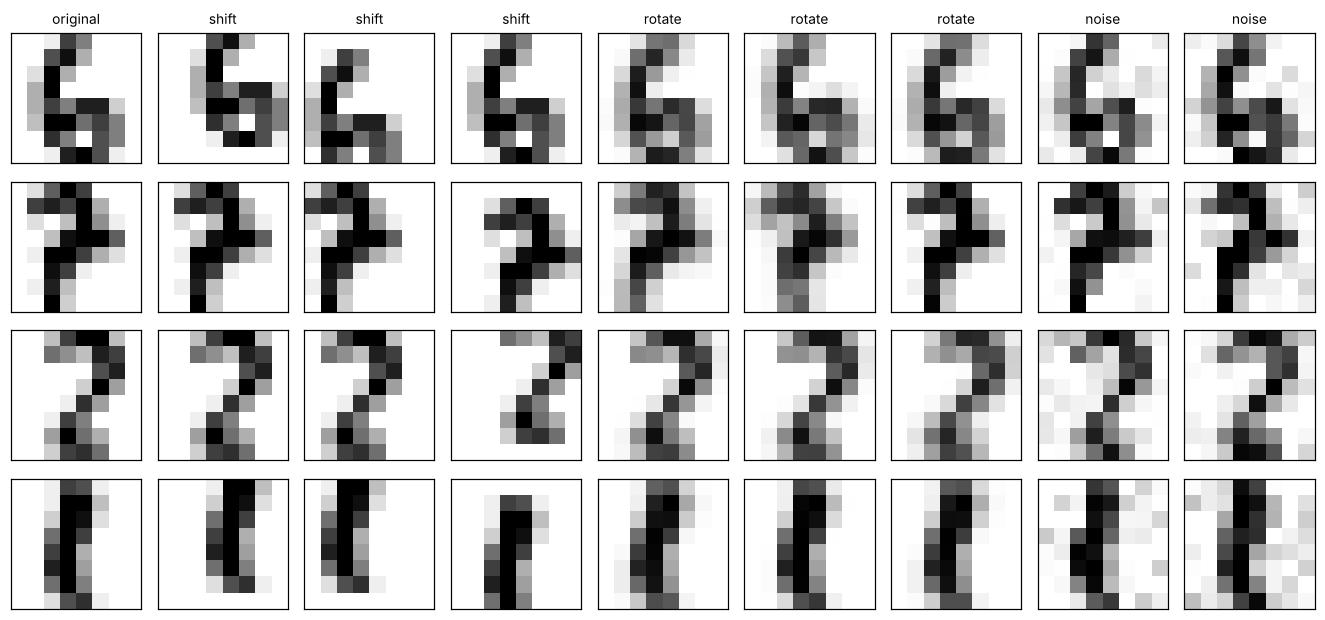

In [3]:
set_seed(5)
base = Xpool_t[[0, 1, 2, 3]]
cols = [("original", None)] + [("shift", dict(p=1, max_shift=1))] * 3 + [("rotate", dict(p=1, max_rot=10))] * 3 + [("noise", dict(p=1, noise=0.1))] * 2
fig, axes = plt.subplots(4, len(cols), figsize=(1.35 * len(cols), 5.8))
for c, (name, kw) in enumerate(cols):
    out = base if kw is None else augment(base, **kw)
    for r in range(4):
        axes[r, c].imshow(out[r].view(8, 8), cmap="gray_r", vmin=0, vmax=1); axes[r, c].set_xticks([]); axes[r, c].set_yticks([]); axes[r, c].grid(False)
    axes[0, c].set_title(name, fontsize=9)
plt.tight_layout(); plt.show()

## 2. The network, the training loop and the test sets

The same family as before: an MLP with **2 hidden layers of 256 ReLU units**, Adam (`lr = 1e-3`), batch size 32, **no dropout, no weight decay, no early stopping**, 300 epochs. Training uses **200 / 300 / 700 images** drawn from the pool, depending on the experiment (the main one uses 300). Augmentation is applied **online**: a fresh random augmentation of every batch at every step.

We evaluate on four versions of the same 500 held-out test images, with the transformations fixed once (same random draws for every model):

| Test set | What it is |
|---|---|
| **clean** | the original test images (ordinary in-distribution accuracy) |
| **shifted** | every image shifted by up to 1 pixel in each direction |
| **rotated** | every image rotated by up to 10 degrees |
| **noisy** | Gaussian noise (std 0.1) added to every pixel |

The shifted / rotated / noisy sets are **robustness** tests. Note that they test exactly the changes the corresponding augmentation trains for, so doing well on them shows that the network *learned the invariance we taught it*; it is not independent evidence of better generalization. The clean test accuracy is the honest measure of ordinary generalization.

In [4]:
with torch.random.fork_rng():                    # fixed test-time transformations, identical for every model
    torch.manual_seed(1234); TESTSETS = {
        "clean": Xte_t,
        "shifted": augment(Xte_t, p=1.0, max_shift=1),
        "rotated": augment(Xte_t, p=1.0, max_rot=10),
        "noisy": augment(Xte_t, p=1.0, noise=0.1),
    }


def make_mlp(width=256):
    return nn.Sequential(nn.Linear(64, width), nn.ReLU(), nn.Linear(width, width), nn.ReLU(), nn.Linear(width, 10))


def fit(n=300, aug=None, epochs=300, seed=0, width=256, batch_size=32):
    set_seed(seed)
    X, y = Xpool_t[:n], ypool_t[:n]
    model = make_mlp(width)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    g = torch.Generator().manual_seed(seed)
    hist = dict(val_acc=[], train_acc=[])
    for _ in range(epochs):
        model.train()
        perm = torch.randperm(n, generator=g)
        for i in range(0, n, batch_size):
            idx = perm[i:i + batch_size]
            xb = augment(X[idx], **aug) if aug else X[idx]
            opt.zero_grad()
            F.cross_entropy(model(xb), y[idx]).backward(); opt.step()
        model.eval()
        with torch.no_grad():
            hist["val_acc"].append((model(Xva_t).argmax(1) == yva_t).float().mean().item())
            hist["train_acc"].append((model(X).argmax(1) == y).float().mean().item())
    with torch.no_grad():
        res = {k: (model(v).argmax(1) == yte_t).float().mean().item() for k, v in TESTSETS.items()}
    return model, hist, res


t0 = time.time(); _ = fit(300, None, epochs=20); print(f"one 20-epoch run takes {time.time() - t0:.1f}s")
print(make_mlp())

one 20-epoch run takes 1.2s
Sequential(
  (0): Linear(in_features=64, out_features=256, bias=True)
  (1): ReLU()
  (2): Linear(in_features=256, out_features=256, bias=True)
  (3): ReLU()
  (4): Linear(in_features=256, out_features=10, bias=True)
)


## 3. With and without augmentation

300 training images; **no augmentation** against **shift augmentation** (each batch image is shifted by up to 1 pixel with probability 0.5, chosen in advance as a moderate setting; section 4 explores other values). 5 seeds each.

trained 10 networks in 44s


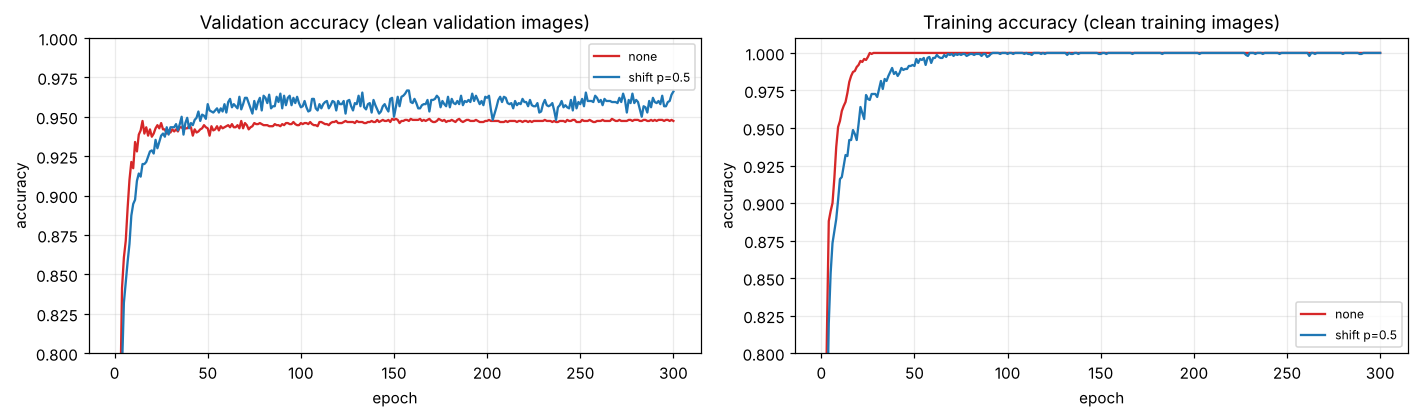

training                  clean          shifted          rotated            noisy     (test accuracy, mean +- std over 5 seeds)
none               0.946+-0.003     0.374+-0.008     0.940+-0.005     0.936+-0.003
shift p=0.5        0.964+-0.004     0.936+-0.011     0.938+-0.004     0.948+-0.007

per-seed change in clean test accuracy from augmentation: [0.016 0.014 0.01  0.016 0.03 ] | seeds improved: 5 of 5


In [5]:
AUG_SHIFT = dict(p=0.5, max_shift=1)
SEEDS = range(5)
main = {}
t0 = time.time()
for name, aug in (("none", None), ("shift p=0.5", AUG_SHIFT)):
    main[name] = [fit(300, aug, epochs=300, seed=s) for s in SEEDS]
print(f"trained 10 networks in {time.time() - t0:.0f}s")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.9))
cols = {"none": "C3", "shift p=0.5": "C0"}
for name, runs in main.items():
    ep = np.arange(1, 301)
    axes[0].plot(ep, np.mean([r[1]["val_acc"] for r in runs], 0), color=cols[name], label=name)
    axes[1].plot(ep, np.mean([r[1]["train_acc"] for r in runs], 0), color=cols[name], label=name)
axes[0].set_title("Validation accuracy (clean validation images)"); axes[1].set_title("Training accuracy (clean training images)")
axes[0].set_ylim(0.8, 1.0); axes[1].set_ylim(0.8, 1.01)
for ax in axes:
    ax.set_xlabel("epoch"); ax.set_ylabel("accuracy"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"{'training':<14} " + " ".join(f"{k:>16}" for k in TESTSETS) + "     (test accuracy, mean +- std over 5 seeds)")
for name, runs in main.items():
    print(f"{name:<14} " + " ".join(f"{np.mean([r[2][k] for r in runs]):>9.3f}+-{np.std([r[2][k] for r in runs]):.3f}" for k in TESTSETS))
d_clean = [a[2]["clean"] - b[2]["clean"] for a, b in zip(main["shift p=0.5"], main["none"])]
print("\nper-seed change in clean test accuracy from augmentation:", np.round(d_clean, 3), "| seeds improved:", sum(x > 0 for x in d_clean), "of 5")

**What to notice.**

- **Clean accuracy improves.** Shift augmentation raises test accuracy on the ordinary, centered test images from **0.946 to 0.964** (+1.8 points, about 9 of the 500 test images), and it helps in **all 5 seeds** (by 1.0 to 3.0 points). That is a modest but consistent gain in ordinary generalization.
- **Robustness to shifts changes completely.** The plain network, which scores 0.946 on clean images, falls to **0.374** when each image is shifted by at most one pixel: a plain MLP has no idea that a shifted digit is the same digit. The augmented network scores **0.936** on the same shifted images. (This column measures the invariance we trained for, so it demonstrates what augmentation teaches rather than independent generalization.)
- **Other conditions.** Rotated images are unchanged (0.940 against 0.938: shift augmentation does not teach rotation) and noisy images improve slightly (0.936 to 0.948), a small gain I did not investigate further.
- **The training curves** show the price. The plain network fits the training set perfectly by epoch 26 and its validation accuracy then stalls at about 0.947. The augmented network lags for the first ~40 epochs and takes about 70 epochs to fit the training set; it overtakes the plain network in validation accuracy at epoch 41 and settles at about 0.96.

## 4. How much augmentation? And a longer training budget

Two knobs: the **probability `p`** that a given training image is augmented (0 means none, 1 means every image is shifted at every step, so the network *never* sees an original image except by chance when the random shift happens to be 0), and the **number of epochs**. We expect augmentation to make the training problem harder, so it should need more epochs to pay off.

### 4a. Augmentation probability (300 epochs, 5 seeds)

done in 47s


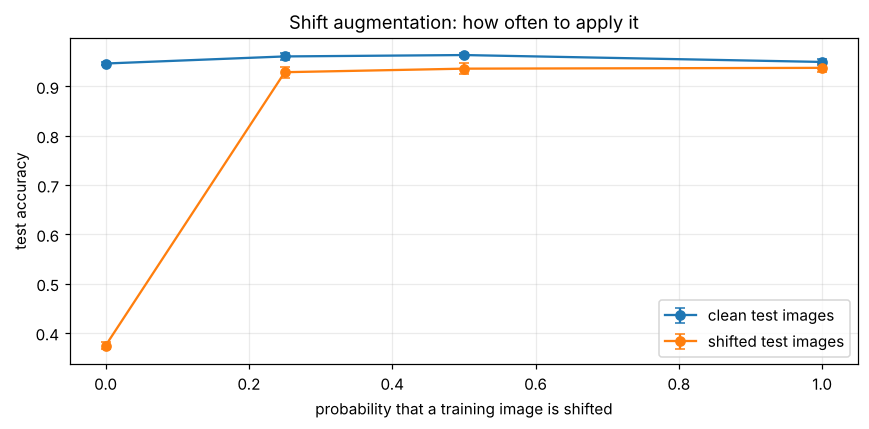

    p | train acc  val acc  clean test  shifted test
  0.0 |     1.000    0.947       0.946         0.374
 0.25 |     1.000    0.966       0.961         0.929
  0.5 |     1.000    0.966       0.964         0.936
  1.0 |     1.000    0.954       0.950         0.938

best probability chosen on the VALIDATION set: p = 0.5


In [6]:
t0 = time.time()
PROBS = [0.0, 0.25, 0.5, 1.0]
sweep_p = {0.0: main["none"], 0.5: main["shift p=0.5"]}
for p in (0.25, 1.0):
    sweep_p[p] = [fit(300, dict(p=p, max_shift=1), epochs=300, seed=s) for s in SEEDS]
print(f"done in {time.time() - t0:.0f}s")

fig, ax = plt.subplots(figsize=(8, 4))
for k, c in (("clean", "C0"), ("shifted", "C1")):
    ax.errorbar(PROBS, [np.mean([r[2][k] for r in sweep_p[p]]) for p in PROBS], yerr=[np.std([r[2][k] for r in sweep_p[p]]) for p in PROBS],
                marker="o", capsize=3, color=c, label=f"{k} test images")
ax.set_xlabel("probability that a training image is shifted"); ax.set_ylabel("test accuracy"); ax.set_title("Shift augmentation: how often to apply it"); ax.legend()
plt.tight_layout(); plt.show()

print(f"{'p':>5} | {'train acc':>9} {'val acc':>8} {'clean test':>11} {'shifted test':>13}")
for p in PROBS:
    rs = sweep_p[p]
    print(f"{p:>5} | {np.mean([r[1]['train_acc'][-1] for r in rs]):>9.3f} {np.mean([r[1]['val_acc'][-1] for r in rs]):>8.3f} {np.mean([r[2]['clean'] for r in rs]):>11.3f} {np.mean([r[2]['shifted'] for r in rs]):>13.3f}")
best_p = max(PROBS, key=lambda p: np.mean([r[1]["val_acc"][-1] for r in sweep_p[p]]))
print(f"\nbest probability chosen on the VALIDATION set: p = {best_p}")

**What to notice.** Even a quarter of the images shifted (`p = 0.25`) is enough to lift the shifted-test accuracy from 0.37 to 0.93. For **clean** accuracy a moderate amount is best: 0.961 at `p = 0.25` and 0.964 at `p = 0.5`, against 0.946 without augmentation. At `p = 1.0` (every training image shifted at every step) robustness is highest (0.938), but the clean-image gain nearly disappears (0.950, only +0.4 points) and the validation accuracy is the lowest of the three augmented settings. A plausible reason is that the network then almost never sees an unshifted training image (a shift of (0, 0) occurs with probability 1/9), even though clean test images are what we measure; I did not test this explanation directly. The validation set picks `p = 0.5` (tied with 0.25), which is what we use as the default from here on.

### 4b. Augmentation needs a longer training budget

Clean-test accuracy after 30, 60, 150 and 300 epochs for no augmentation, moderate (`p = 0.5`) and full (`p = 1.0`) shift augmentation (3 seeds each).

done in 71s


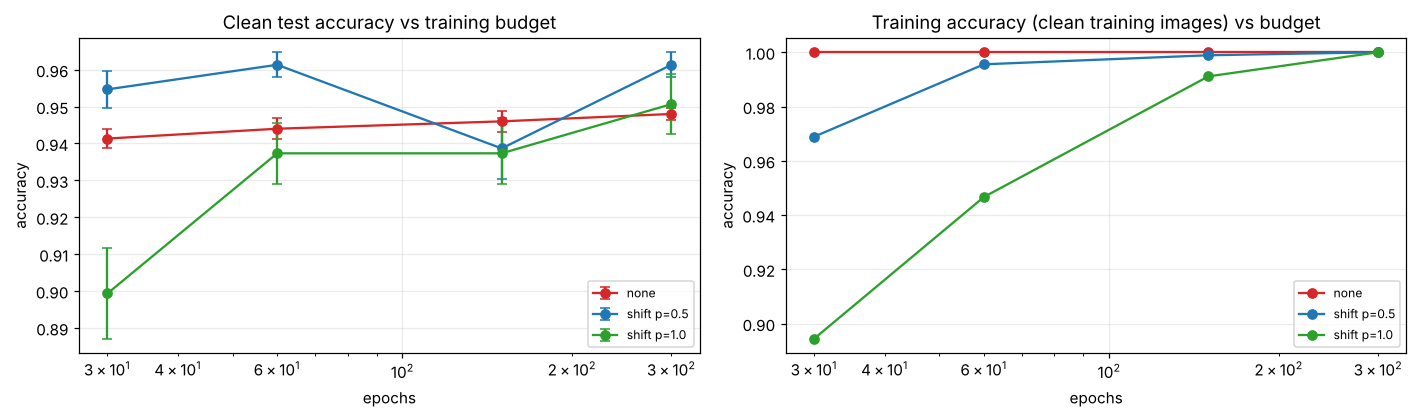

                          30            60           150           300    <- clean test accuracy at this many epochs
none                   0.941         0.944         0.946         0.948
shift p=0.5            0.955         0.961         0.939         0.961
shift p=1.0            0.899         0.937         0.937         0.951


In [7]:
t0 = time.time()
EPOCH_LIST = [30, 60, 150, 300]
budget = {}
for label, aug in (("none", None), ("shift p=0.5", dict(p=0.5, max_shift=1)), ("shift p=1.0", dict(p=1.0, max_shift=1))):
    for e in EPOCH_LIST:
        budget[(label, e)] = [fit(300, aug, epochs=e, seed=s) for s in range(3)]
print(f"done in {time.time() - t0:.0f}s")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.9))
for label, c in (("none", "C3"), ("shift p=0.5", "C0"), ("shift p=1.0", "C2")):
    axes[0].errorbar(EPOCH_LIST, [np.mean([r[2]["clean"] for r in budget[(label, e)]]) for e in EPOCH_LIST], yerr=[np.std([r[2]["clean"] for r in budget[(label, e)]]) for e in EPOCH_LIST], marker="o", capsize=3, color=c, label=label)
    axes[1].plot(EPOCH_LIST, [np.mean([r[1]["train_acc"][-1] for r in budget[(label, e)]]) for e in EPOCH_LIST], marker="o", color=c, label=label)
axes[0].set_xscale("log"); axes[1].set_xscale("log")
axes[0].set_title("Clean test accuracy vs training budget"); axes[1].set_title("Training accuracy (clean training images) vs budget")
for ax in axes:
    ax.set_xlabel("epochs"); ax.set_ylabel("accuracy"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"{'':<14}" + "".join(f"{e:>14}" for e in EPOCH_LIST) + "    <- clean test accuracy at this many epochs")
for label in ("none", "shift p=0.5", "shift p=1.0"):
    print(f"{label:<14}" + "".join(f"{np.mean([r[2]['clean'] for r in budget[(label, e)]]):>14.3f}" for e in EPOCH_LIST))

**What to notice.** Augmentation makes the fitting problem harder, and **full-strength augmentation needs a much longer budget**: with `p = 1.0` the training accuracy on clean training images is only 0.89 after 30 epochs, 0.95 after 60 and 0.99 after 150, reaching 1.00 at 300, and its clean test accuracy stays *below* the plain network's (0.899, 0.937, 0.937) until the 300-epoch point (0.951 against 0.948, a tie). Judged after a short run, heavy augmentation looks harmful.

Moderate augmentation (`p = 0.5`) pays off much sooner: it is already ahead of the plain network after 30 epochs (0.955 against 0.941) and 60 epochs (0.961 against 0.944), and at 300 epochs (0.961 against 0.948). Its dip at 150 epochs (0.939) is odd, but with 3 seeds and error bars that overlap the plain network's it looks like seed noise rather than a real effect. The plain network barely changes between 30 and 300 epochs (0.941 to 0.948), since it has fitted the training set long before.

## 5. Which augmentation teaches which invariance?

Train with each kind of augmentation (300 epochs, 300 images, 3 seeds; each applied to half of the batch images) and test on all four versions of the test set. Each row is a training recipe, each column a test condition.

done in 69s



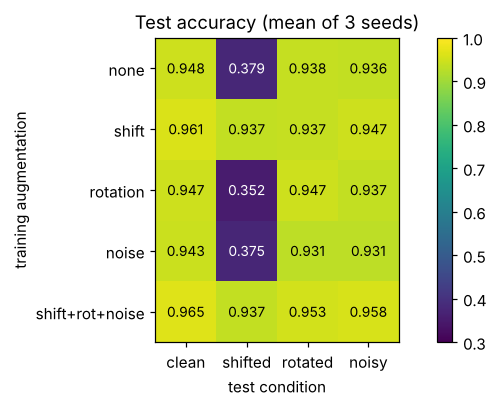

                      clean   shifted   rotated     noisy
none                  0.948     0.379     0.938     0.936
shift                 0.961     0.937     0.937     0.947
rotation              0.947     0.352     0.947     0.937
noise                 0.943     0.375     0.931     0.931
shift+rot+noise       0.965     0.937     0.953     0.958


In [8]:
RECIPES = {
    "none": None,
    "shift": dict(p=0.5, max_shift=1),
    "rotation": dict(p=0.5, max_rot=10),
    "noise": dict(p=0.5, noise=0.1),
    "shift+rot+noise": dict(p=0.5, max_shift=1, max_rot=10, noise=0.1),
}
t0 = time.time()
recipe_res = {name: [fit(300, aug, epochs=300, seed=s)[2] for s in range(3)] for name, aug in RECIPES.items()}
print(f"done in {time.time() - t0:.0f}s\n")

tests = list(TESTSETS)
M = np.array([[np.mean([r[t] for r in recipe_res[name]]) for t in tests] for name in RECIPES])
fig, ax = plt.subplots(figsize=(7.5, 3.8))
im = ax.imshow(M, cmap="viridis", vmin=0.3, vmax=1.0); ax.grid(False)
ax.set_xticks(range(len(tests))); ax.set_xticklabels(tests); ax.set_yticks(range(len(RECIPES))); ax.set_yticklabels(list(RECIPES))
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        ax.text(j, i, f"{M[i, j]:.3f}", ha="center", va="center", color="white" if M[i, j] < 0.75 else "black", fontsize=9)
ax.set_xlabel("test condition"); ax.set_ylabel("training augmentation"); ax.set_title("Test accuracy (mean of 3 seeds)")
plt.colorbar(im, fraction=0.04); plt.tight_layout(); plt.show()
print(f"{'':<17}" + "".join(f"{t:>10}" for t in tests))
for name, row in zip(RECIPES, M):
    print(f"{name:<17}" + "".join(f"{v:>10.3f}" for v in row))

**What to notice.** Each augmentation buys **the invariance it teaches, and little else**:

- **Shift** raises shifted-test accuracy from 0.379 to 0.937 and clean accuracy from 0.948 to 0.961, but does nothing for rotation (0.937 against 0.938).
- **Rotation (up to 10 degrees)** gives a small gain on rotated images (0.938 to 0.947), nothing on clean images (0.947) and nothing for shifts (0.352). Note that a 10-degree rotation barely hurt the plain network in the first place, so there was little room to improve.
- **Noise (std 0.1)** shows **no measurable benefit** anywhere, not even on the noisy test set (0.931 against 0.936 for the plain network, i.e. within seed noise).
- **All three together** is best or tied in every column (0.965 clean, 0.953 rotated, 0.958 noisy), though its clean-accuracy edge over shift alone (0.965 against 0.961) is within the noise of 3 seeds.

The plain MLP is hardly bothered by mild rotation or noise (drops of at most about 1 point); its one big weakness is **translation** (a drop of 57 points), and that is exactly where augmentation pays. Augmentation helps most where the network is most fragile, and the useful transformations are the ones that match real variation in the data.

## 6. How does it depend on the amount of training data?

Same comparison (none against shift with `p = 0.5`, 300 epochs, 3 seeds) with 100, 300 and 700 training images. A caveat to keep in mind: with a fixed number of *epochs*, the smaller training sets get fewer optimizer steps.

done in 93s


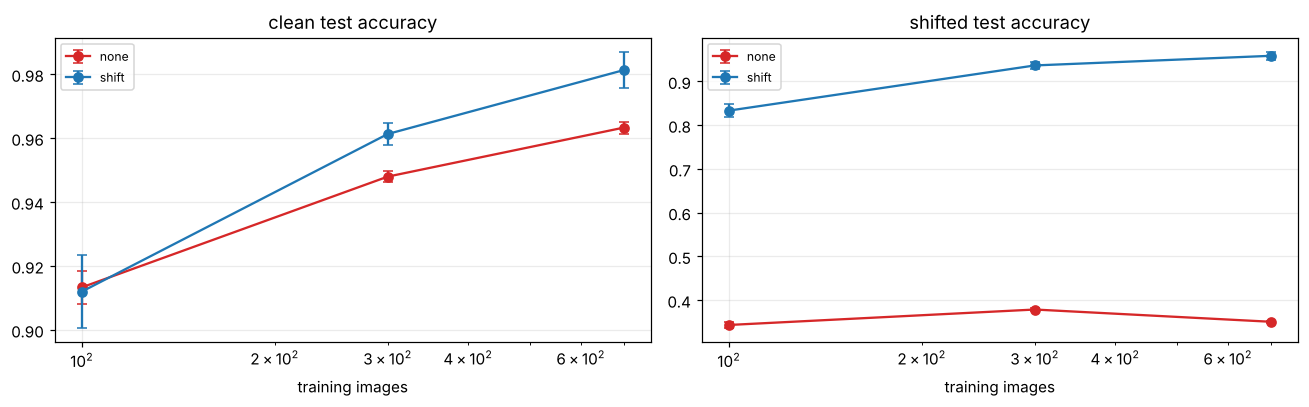

    n |  clean: none   shift   gain |  shifted: none   shift
  100 |        0.913   0.912 -0.001 |          0.343   0.833
  300 |        0.948   0.961 +0.013 |          0.379   0.937
  700 |        0.963   0.981 +0.018 |          0.351   0.959


In [9]:
t0 = time.time()
SIZES = [100, 300, 700]
size_res = {(n, name): [fit(n, aug, epochs=300, seed=s)[2] for s in range(3)] for n in SIZES for name, aug in (("none", None), ("shift", AUG_SHIFT))}
print(f"done in {time.time() - t0:.0f}s")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for name, c in (("none", "C3"), ("shift", "C0")):
    for ax, k in zip(axes, ("clean", "shifted")):
        ax.errorbar(SIZES, [np.mean([r[k] for r in size_res[(n, name)]]) for n in SIZES], yerr=[np.std([r[k] for r in size_res[(n, name)]]) for n in SIZES],
                    marker="o", capsize=3, color=c, label=name)
        ax.set_title(f"{k} test accuracy"); ax.set_xlabel("training images"); ax.set_xscale("log"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"{'n':>5} | {'clean: none':>12} {'shift':>7} {'gain':>6} | {'shifted: none':>14} {'shift':>7}")
for n in SIZES:
    a, b = [np.mean([r["clean"] for r in size_res[(n, k)]]) for k in ("none", "shift")]
    c, d = [np.mean([r["shifted"] for r in size_res[(n, k)]]) for k in ("none", "shift")]
    print(f"{n:>5} | {a:>12.3f} {b:>7.3f} {b - a:>+6.3f} | {c:>14.3f} {d:>7.3f}")

**What to notice.** The robustness gain is large at every size (shifted accuracy from about 0.35 to 0.83, 0.94 and 0.96 for 100, 300 and 700 images). The **clean**-accuracy gain, however, goes the opposite way from the usual rule of thumb that augmentation helps most with little data: it is **nothing at 100 images** (0.913 against 0.912, with large seed-to-seed variation), **+1.3 points at 300** and **+1.8 points at 700**. Two possible reasons, neither tested here: with only 100 images the network may simply not have enough examples to learn the invariance, and with a fixed number of epochs the smaller set gets far fewer optimizer steps (1,200 against 6,600 at 700 images). The honest summary is that on this problem augmentation was not a remedy for tiny training sets, and gave a steady modest gain from a few hundred images upward.

## 7. What about tabular data?

For the breast-cancer and wine networks we trained earlier, there is no spatial structure to shift. The usual generic option is to add **Gaussian noise** to the (standardized) features, which asks the network to give the same answer for slightly perturbed inputs. We test noise levels of 0, 0.1, 0.3 and 0.6 standard deviations (2 hidden layers of 64 units, Adam, 200 epochs, 5 seeds). The noise is added fresh to every training batch; validation and test data are clean.

In [10]:
def tab_run(loader, sigma, seed, epochs=200):
    d = loader(); X, y = d.data, d.target
    Xtr, Xr, ytr, yr = train_test_split(X, y, test_size=0.4, stratify=y, random_state=0)
    Xva, Xte, yva, yte = train_test_split(Xr, yr, test_size=0.5, stratify=yr, random_state=0)
    S = StandardScaler().fit(Xtr)                              # scaler fitted on the training split only
    t = lambda a: torch.tensor(S.transform(a), dtype=torch.float32)
    Xtr_, Xva_, Xte_, ytr_ = t(Xtr), t(Xva), t(Xte), torch.tensor(ytr)
    set_seed(seed); g = torch.Generator().manual_seed(seed)
    m = nn.Sequential(nn.Linear(X.shape[1], 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, len(np.unique(y))))
    opt = torch.optim.Adam(m.parameters(), 1e-3); n = len(Xtr_)
    for _ in range(epochs):
        perm = torch.randperm(n, generator=g)
        for i in range(0, n, 32):
            idx = perm[i:i + 32]; xb = Xtr_[idx]
            if sigma > 0:
                xb = xb + sigma * torch.randn_like(xb)
            opt.zero_grad(); F.cross_entropy(m(xb), ytr_[idx]).backward(); opt.step()
    m.eval()
    with torch.no_grad():
        return [(m(Z).argmax(1).numpy() == yy).mean() for Z, yy in ((Xva_, yva), (Xte_, yte))]


t0 = time.time()
SIGMAS = [0.0, 0.1, 0.3, 0.6]
tab = {(nm, s): np.array([tab_run(ld, s, seed) for seed in SEEDS]) for nm, ld in (("breast_cancer", load_breast_cancer), ("wine", load_wine)) for s in SIGMAS}
print(f"done in {time.time() - t0:.0f}s\n")
print(f"{'dataset':<14} {'noise std':>9} | {'val acc':>8} {'test acc (mean +- std, 5 seeds)':>34}")
for nm in ("breast_cancer", "wine"):
    for s in SIGMAS:
        r = tab[(nm, s)]
        print(f"{nm:<14} {s:>9} | {r[:, 0].mean():>8.3f} {r[:, 1].mean():>20.3f} +- {r[:, 1].std():.3f}")

done in 33s

dataset        noise std |  val acc    test acc (mean +- std, 5 seeds)
breast_cancer        0.0 |    0.958                0.970 +- 0.004
breast_cancer        0.1 |    0.961                0.970 +- 0.004
breast_cancer        0.3 |    0.967                0.968 +- 0.007
breast_cancer        0.6 |    0.967                0.963 +- 0.009
wine                 0.0 |    0.989                0.967 +- 0.021
wine                 0.1 |    0.989                0.967 +- 0.021
wine                 0.3 |    0.978                0.972 +- 0.018
wine                 0.6 |    0.972                0.967 +- 0.011


**What to notice.** On both tabular datasets, noise augmentation **does nothing measurable**: breast-cancer test accuracy is 0.970, 0.970, 0.968 and 0.963 for noise levels 0, 0.1, 0.3 and 0.6, and wine is 0.967, 0.967, 0.972 and 0.967, all within seed-to-seed variation (standard deviations 0.004 to 0.021); the drop at 0.6 on breast cancer is about one standard deviation. This is unsurprising: nothing tells us that a tumour's measurements *should* be perturbed by Gaussian noise without changing its diagnosis, so noise is a generic smoothing device rather than a real invariance, and these networks were not overfitting badly to begin with (validation accuracy 0.96 to 0.99). Augmentation is most useful when you know a **meaningful, label-preserving transformation** of your data, as with shifts of an image.

## 8. Summary

**Does data augmentation help our 2-hidden-layer networks?** On image-like data, **yes**; on the tabular data we tried, **no**.

**What this notebook found**

1. **On digits (section 3), shift augmentation helps in two ways.** Clean test accuracy rises from 0.946 to 0.964 (all 5 seeds improve), and accuracy on shifted images goes from **0.374 to 0.936**: the plain MLP loses 57 points under a one-pixel shift.
2. **Moderate is best (4a).** Augmenting a quarter to a half of the images gave the best clean accuracy; augmenting every image gave the best robustness but almost no clean gain.
3. **It costs training time (4b).** Moderate augmentation pays off within 30 to 60 epochs, but full-strength augmentation needs about 10 times more epochs just to match the plain network's accuracy; judging it after a short run is misleading.
4. **It teaches only what you show it (section 5).** Shift augmentation fixes shifts and nothing else; rotation and noise gave no measurable gain on clean images, and noise gave none even on noisy ones.
5. **It was not a fix for tiny datasets here (section 6).** No clean-accuracy gain at 100 images, +1.3 to +1.8 points at 300 to 700.
6. **No help on tabular data (section 7).** Gaussian noise left breast-cancer and wine accuracy unchanged.

**Practical notes**

- Augment **only the training data**, online (a fresh random draw each step), and keep validation and test data untouched, apart from deliberate robustness test sets.
- Choose transformations that **preserve the label and match real variation**. Even here, a 1-pixel shift of an 8x8 digit sometimes clips part of a stroke (see the figure in section 1a). A horizontal flip would be wrong for digits (a flipped "2" or "5" is not a digit).
- Tune the **amount** of augmentation (the probability and the strength) on the validation set, and train long enough: augmented training converges more slowly.
- A convolutional network gets much of its shift robustness from its architecture; we did not test that here, so we cannot say how much of the benefit shown for the MLP a CNN would have anyway.
- Augmentation is not the only regularizer: dropout and weight decay act differently, and we did not test how they combine.

**Try it yourself**

1. Try 2-pixel shifts. Where does the benefit turn into harm?
2. Add a horizontal flip and check which digits it breaks.
3. Replace the MLP with a small convolutional network and repeat sections 3 and 5: how much of the shift robustness does the architecture give for free?
4. Combine shift augmentation with dropout and compare against each alone.
5. Use **test-time augmentation**: average the network's predictions over a few shifted copies of each test image. Does it help the plain network on shifted images?
6. Repeat the 100-image experiment with the same number of optimizer *steps* as the 700-image one, to test the "fewer steps" explanation in section 6.